In [2]:
import cv2
import numpy as np
import  matplotlib.pyplot as plt
from skimage import data

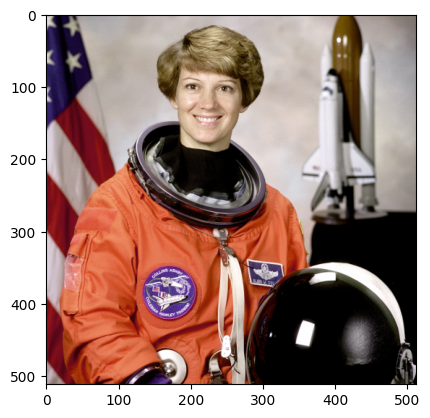

In [3]:
plt.imshow(data.astronaut())

In [4]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.subplot(1,2,1)
  plt.imshow(img)
  plt.title('Imagem Original')
  plt.axis('off')

  plt.subplot(1,2,2)
  plt.imshow(img_filt)
  plt.title('Filtro ' + nomefiltro + ' ' + kernelsize)
  plt.axis('off')

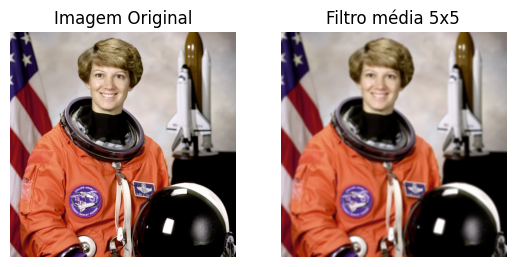

In [5]:
img = data.astronaut()
img_filt = cv2.blur(img, (5,5))
implot(img, img_filt, 'média', '5x5')

### 2 - Filtro de

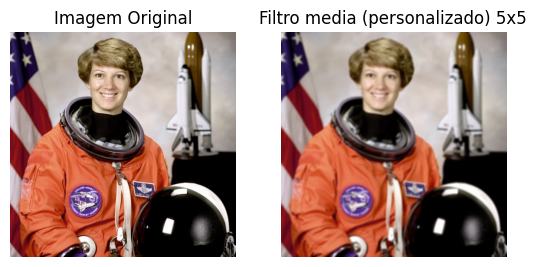

In [6]:
kernel = np.array([
    [1,1,1,1,1],
    [1,1,1,1,1],
    [1,1,1,1,1],
    [1,1,1,1,1],
    [1,1,1,1,1]
    ])

kernel = kernel / np.sum(kernel)

img_filt = cv2.filter2D(img, -1, kernel)
implot(img, img_filt, 'media (personalizado)', '5x5')

### 3 - Filtro de aguçamento (sharpen)

In [7]:
kernel = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
])

img_filt = cv2.filter2D

### Desafio: filtros lineares e não-lineares implementados manualmente

In [8]:
img_cinza = data.camera()
print(img_cinza.shape, img_cinza.dtype)

(512, 512) uint8


In [9]:
def implot_cinza(img, img_filt, nomefiltro, kernelsize):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Imagem Original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_filt, cmap='gray', vmin=0, vmax=255)
    plt.title('Filtro ' + nomefiltro + ' ' + kernelsize)
    plt.axis('off')

    plt.show()

In [10]:
def convolucao(img, kernel):
    altura, largura = img.shape
    k_alt, k_larg = kernel.shape
    pad_y, pad_x = k_alt // 2, k_larg // 2

    kernel = np.flipud(np.fliplr(kernel))

    img_pad = np.pad(img.astype(np.float64), ((pad_y, pad_y), (pad_x, pad_x)), mode='edge')
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            regiao = img_pad[i:i + k_alt, j:j + k_larg]
            saida[i, j] = np.sum(regiao * kernel)

    return np.clip(np.round(saida), 0, 255).astype(np.uint8)

In [11]:
def janela_deslizante(img, tamanho, operacao):
    altura, largura = img.shape
    pad = tamanho // 2
    img_pad = np.pad(img, pad, mode='edge')
    saida = np.zeros_like(img)

    for i in range(altura):
        for j in range(largura):
            regiao = img_pad[i:i + tamanho, j:j + tamanho]
            saida[i, j] = operacao(regiao)

    return saida

In [13]:
def filtro_media(img, tamanho=5):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    return convolucao(img, kernel)

def filtro_mediana(img, tamanho=5):
    def mediana(regiao):
        valores = np.sort(regiao.ravel())
        return valores[len(valores) // 2]
    return janela_deslizante(img, tamanho, mediana)

def filtro_moda(img, tamanho=5):
    def moda(regiao):
        return np.bincount(regiao.ravel(), minlength=256).argmax()
    return janela_deslizante(img, tamanho, moda)

def filtro_maxima(img, tamanho=5):
    def maxima(regiao):
        return regiao.max()
    return janela_deslizante(img, tamanho, maxima)

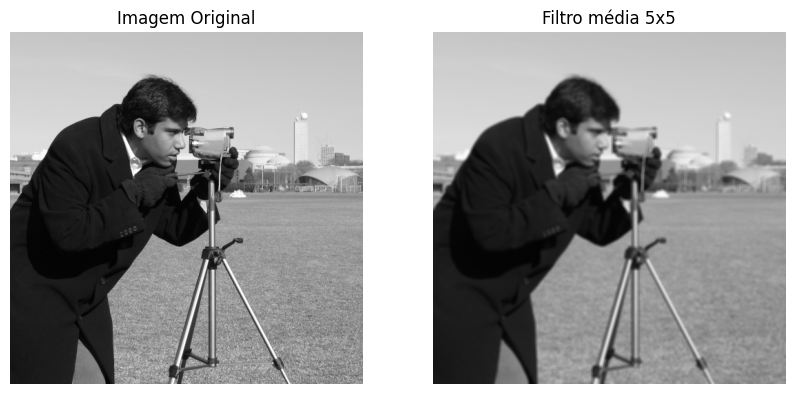

In [14]:
img_filt = filtro_media(img_cinza, 5)
implot_cinza(img_cinza, img_filt, 'média', '5x5')

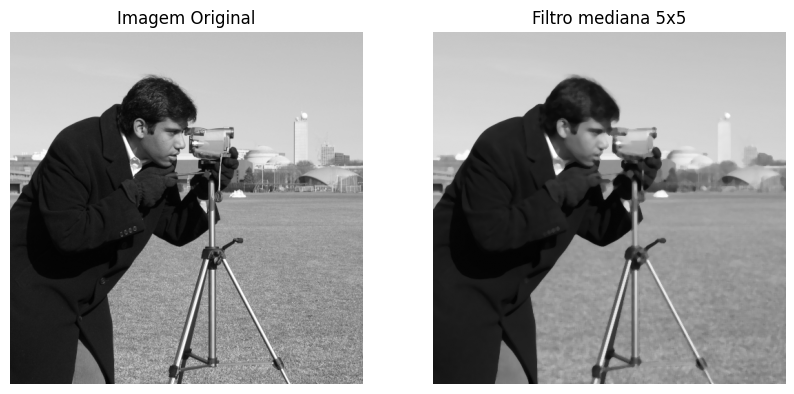

In [15]:
img_filt = filtro_mediana(img_cinza, 5)
implot_cinza(img_cinza, img_filt, 'mediana', '5x5')

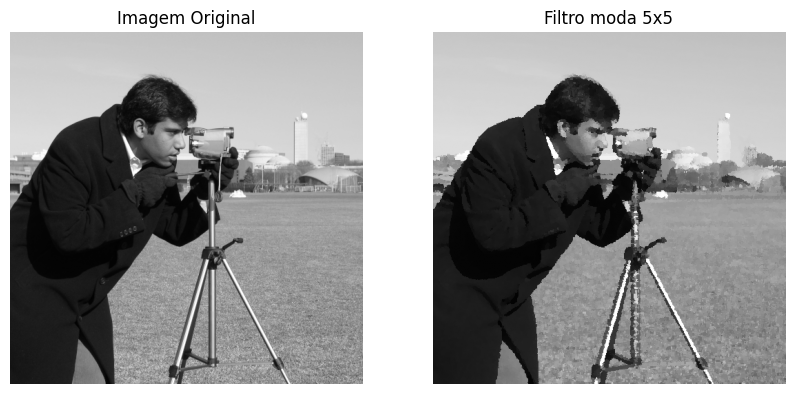

In [16]:
img_filt = filtro_moda(img_cinza, 5)
implot_cinza(img_cinza, img_filt, 'moda', '5x5')

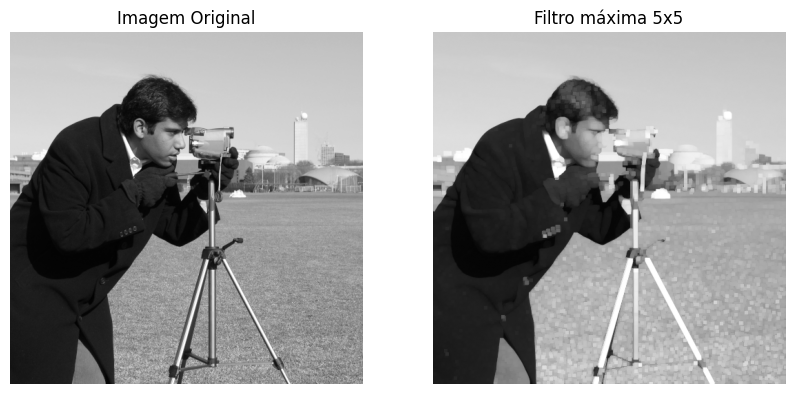

In [17]:
img_filt = filtro_maxima(img_cinza, 5)
implot_cinza(img_cinza, img_filt, 'máxima', '5x5')